# Credit Card Fraud Detection

## Step 1: Problem Framing & Theory Notes

### 1.1 Why is Accuracy a terrible metric for fraud detection? If 99.83% of transactions are legitimate and your model predicts everything as 'Not Fraud', what accuracy does it achieve? What is the Precision and Recall for the Fraud class in that case?
In payment fraud detection, **Accuracy is subject to the Accuracy Paradox**:
* In a dataset where 99.83% of transactions are legitimate and 0.17% are fraudulent, a model predicting *everything as Not Fraud* achieves **99.83% accuracy**.
* For the Fraud class:
  $$\text{Recall} = \frac{0}{492} = 0.00\%$$
  $$\text{Precision} = \text{Undefined / } 0.00\%$$
* **Business Impact:** 100% of fraud escapes undetected. The platform suffers unlimited chargeback losses, payment gateway blacklisting by Visa/Mastercard, and regulatory penalties.

### 1.2 What is the Precision-Recall tradeoff? Draw a simple 2x2 confusion matrix and explain what happens when you lower the classification threshold from 0.5 to 0.2 for the Fraud class.

```
                         Actual Fraud (1)      Actual Legit (0)
Predicted Fraud (1)    True Positive (TP)    False Positive (FP)
Predicted Legit (0)    False Negative (FN)   True Negative (TN)
```
* $\text{Precision} = \frac{TP}{TP + FP}$: When we flag a transaction, how often is it truly fraud?
* $\text{Recall} = \frac{TP}{TP + FN}$: Out of all fraud committed, what percentage did we intercept?
* **Lowering threshold from 0.5 to 0.2:**
  - More borderline transactions get classified as Fraud.
  - $TP \uparrow$ and $FN \downarrow \implies \mathbf{Recall \uparrow}$ (fewer missed frauds).
  - $FP \uparrow \implies \mathbf{Precision \downarrow}$ (more false alarms for the review team).

### 1.3 Explain 3 strategies to handle extreme class imbalance: (a) Random Undersampling, (b) SMOTE Oversampling, (c) class_weight='balanced'. What are the pros and cons of each?

1. **Random Undersampling:** Drops majority class rows to match minority ratio. *Pros:* Fast training. *Cons:* Discards 90%+ of legitimate transaction patterns.
2. **SMOTE:** Synthesizes minority samples along feature-space neighbors. *Pros:* Preserves all majority data. *Cons:* Can generate noisy/unrealistic synthetic samples in high-dimensional PCA space.
3. **`class_weight='balanced'` / `scale_pos_weight`:** Penalizes errors on minority samples inversely proportional to class frequency. *Pros:* Zero data alteration, computationally clean. *Cons:* May require probability recalibration.

### 1.4 What is the Precision-Recall AUC (PR-AUC)? Why is it preferred over ROC-AUC for extreme imbalance datasets?

* ROC-AUC plots $TPR$ vs $FPR = \frac{FP}{FP + TN}$. Since $TN$ is massive (~284,000), even thousands of false positives result in a tiny $FPR$, artificially inflating ROC-AUC to 0.98+.
* PR-AUC pairs Recall with Precision (which directly divides by $TP + FP$). It is exquisitely sensitive to false alarms and provides an honest assessment of minority class separation.

### 1.5 In a fraud detection context, which is more costly: a False Positive (flagging a legit transaction as fraud) or a False Negative (missing real fraud)? Give a specific example of the business impact of each.
* **False Positive (FP):** Legitimate user flagged. Cost = ₹150 analyst review + customer checkout friction.
* **False Negative (FN):** Fraud slips through. Cost = Direct loss of transaction value (~₹4,500) + chargeback fee.
* A False Negative is ~30x more expensive than a False Positive.

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.base import BaseEstimator, TransformerMixin

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import xgboost as xgb
import joblib

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

## Step 2: Dataset Loading, Stratified Sampling & EDA

#### 2.1 Load creditcard.csv. Print .shape and check class distribution using value_counts(normalize=True).

In [4]:
df_full = pd.read_csv('creditcard.csv')
print(f'Full Dataset Shape: {df_full.shape}')
print('Full Class Distribution (%):')
print(df_full['Class'].value_counts(normalize=True) * 100)

Full Dataset Shape: (284807, 31)
Full Class Distribution (%):
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


#### 2.2 Create a stratified sample of 50,000 rows using train_test_split with stratify=y, random_state=42 (use just the first split). Confirm fraud ratio is preserved in the sample.

In [5]:
df_sample, _ = train_test_split(
    df_full,
    train_size=50000,
    stratify=df_full['Class'],
    random_state=42
)
df_sample.reset_index(drop=True, inplace=True)
print(f'\nSampled Shape: {df_sample.shape}')
print('Sampled Class Breakdown:')
print(df_sample['Class'].value_counts())

print('\nSummary Statistics of Time and Amount (Sample):')
print(df_sample[['Time', 'Amount']].describe())


Sampled Shape: (50000, 31)
Sampled Class Breakdown:
Class
0    49914
1       86
Name: count, dtype: int64

Summary Statistics of Time and Amount (Sample):
               Time        Amount
count   50000.00000  50000.000000
mean    94977.93554     86.942063
std     47475.50731    226.984602
min         0.00000      0.000000
25%     54423.50000      5.850000
50%     84852.00000     22.000000
75%    139392.25000     76.275000
max    172787.00000   8360.000000


### 2.2 Exploratory Data Visualizations


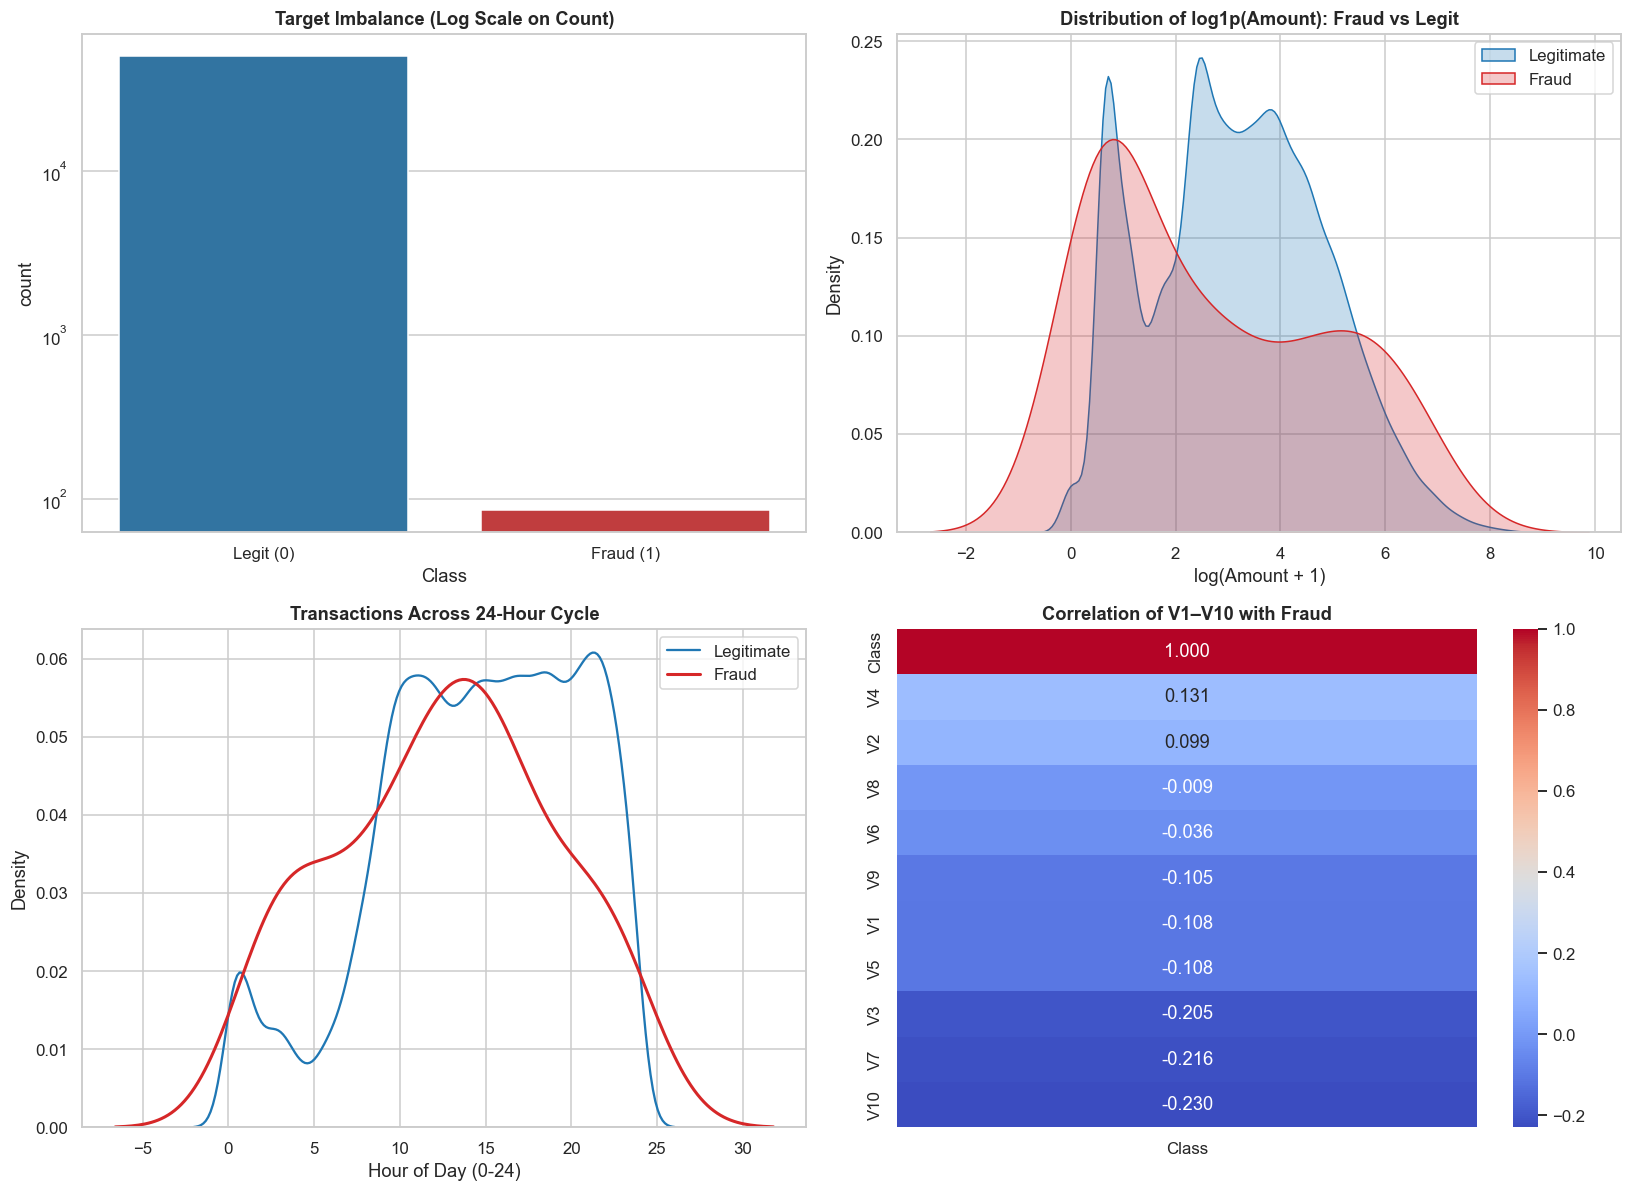

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.countplot(x='Class', data=df_sample, ax=axes[0, 0], palette=['#1f77b4', '#d62728'])
axes[0, 0].set_yscale('log')
axes[0, 0].set_title('Target Imbalance (Log Scale on Count)', fontweight='bold')
axes[0, 0].set_xticklabels(['Legit (0)', 'Fraud (1)'])

sns.kdeplot(np.log1p(df_sample[df_sample['Class'] == 0]['Amount']), ax=axes[0, 1], label='Legitimate', color='#1f77b4', fill=True)
sns.kdeplot(np.log1p(df_sample[df_sample['Class'] == 1]['Amount']), ax=axes[0, 1], label='Fraud', color='#d62728', fill=True)
axes[0, 1].set_title('Distribution of log1p(Amount): Fraud vs Legit', fontweight='bold')
axes[0, 1].set_xlabel('log(Amount + 1)')
axes[0, 1].legend()

sns.kdeplot(df_sample[df_sample['Class'] == 0]['Time'] % 86400 / 3600, ax=axes[1, 0], label='Legitimate', color='#1f77b4')
sns.kdeplot(df_sample[df_sample['Class'] == 1]['Time'] % 86400 / 3600, ax=axes[1, 0], label='Fraud', color='#d62728', lw=2)
axes[1, 0].set_title('Transactions Across 24-Hour Cycle', fontweight='bold')
axes[1, 0].set_xlabel('Hour of Day (0-24)')
axes[1, 0].legend()

v_cols = [f'V{i}' for i in range(1, 11)] + ['Class']
sns.heatmap(df_sample[v_cols].corr()[['Class']].sort_values(by='Class', ascending=False), annot=True, cmap='coolwarm', ax=axes[1, 1], fmt='.3f')
axes[1, 1].set_title('Correlation of V1–V10 with Fraud', fontweight='bold')

plt.tight_layout()
plt.show()

## Step 3: Data Preprocessing & Feature Engineering

#### 3.1 Feature Engineering


In [8]:
df_proc = df_sample.copy()
df_proc['Amount_log'] = np.log1p(df_proc['Amount'])
df_proc['Hour'] = ((df_proc['Time'] % 86400) // 3600).astype(int)
df_proc.drop(columns=['Time', 'Amount'], inplace=True)

#### 3.2 Scale Amount_log and Hour (V1-V28 are already PCA scaled)


In [9]:
scaler = StandardScaler()
df_proc[['Amount_log', 'Hour']] = scaler.fit_transform(df_proc[['Amount_log', 'Hour']])

#### 3.3 Train/Test Split (80/20 Stratified)

In [11]:
X = df_proc.drop(columns=['Class'])
y = df_proc['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

#### 3.4 Imbalance Handling Strategies

#### 2. SMOTE (10% minority ratio)

In [12]:
smote = SMOTE(sampling_strategy=0.10, random_state=42)
X_smote, y_smote = smote.fit_resample(X_train, y_train)

#### 3. Undersampling (10% minority ratio)

In [13]:
rus = RandomUnderSampler(sampling_strategy=0.10, random_state=42)
X_under, y_under = rus.fit_resample(X_train, y_train)

In [14]:
print(f'Original Train Set:    Legit = {sum(y_train == 0)}, Fraud = {sum(y_train == 1)}')
print(f'SMOTE Resampled:       Legit = {sum(y_smote == 0)}, Fraud = {sum(y_smote == 1)}')
print(f'Undersampled:          Legit = {sum(y_under == 0)}, Fraud = {sum(y_under == 1)}')
print(f'Untouched Test Set:    Legit = {sum(y_test == 0)}, Fraud = {sum(y_test == 1)}')

Original Train Set:    Legit = 39931, Fraud = 69
SMOTE Resampled:       Legit = 39931, Fraud = 3993
Undersampled:          Legit = 690, Fraud = 69
Untouched Test Set:    Legit = 9983, Fraud = 17


## Step 4: Model Building Logistic Regression & Random Forest

In [15]:
def eval_model(model, X_val, y_val, name, threshold=0.5):
    probs = model.predict_proba(X_val)[:, 1]
    preds = (probs >= threshold).astype(int)
    return {
        'Model': name,
        'Threshold': threshold,
        'Precision': precision_score(y_val, preds, zero_division=0),
        'Recall': recall_score(y_val, preds, zero_division=0),
        'F1-Score': f1_score(y_val, preds, zero_division=0),
        'PR-AUC': average_precision_score(y_val, probs),
        'y_probs': probs
    }

#### 4.1 Logistic Regression 3 Variants

In [16]:
lr_orig = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42).fit(X_train, y_train)
lr_smote = LogisticRegression(class_weight=None, max_iter=1000, random_state=42).fit(X_smote, y_smote)
lr_under = LogisticRegression(class_weight=None, max_iter=1000, random_state=42).fit(X_under, y_under)

res_lr_orig = eval_model(lr_orig, X_test, y_test, 'LR (Balanced Weights)')
res_lr_smote = eval_model(lr_smote, X_test, y_test, 'LR (SMOTE 0.1)')
res_lr_under = eval_model(lr_under, X_test, y_test, 'LR (Undersampled 0.1)')

print(pd.DataFrame([res_lr_orig, res_lr_smote, res_lr_under])[['Model', 'Precision', 'Recall', 'F1-Score', 'PR-AUC']])

                   Model  Precision    Recall  F1-Score    PR-AUC
0  LR (Balanced Weights)   0.065134  1.000000  0.122302  0.781140
1         LR (SMOTE 0.1)   0.309091  1.000000  0.472222  0.813277
2  LR (Undersampled 0.1)   0.228571  0.941176  0.367816  0.812836


#### 4.2 Random Forest Classifier trained on SMOTE data

In [17]:
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_smote, y_smote)
res_rf = eval_model(rf, X_test, y_test, 'Random Forest (SMOTE)')
print(f"\nRF PR-AUC: {res_rf['PR-AUC']:.4f} | F1: {res_rf['F1-Score']:.4f}")


RF PR-AUC: 0.8748 | F1: 0.8750


#### Top 15 Feature Importances

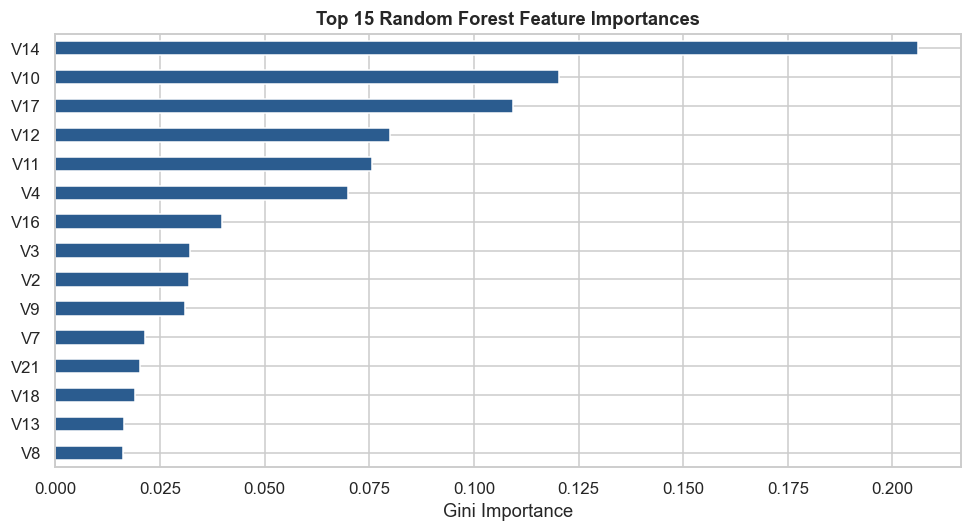

In [18]:
plt.figure(figsize=(9, 5))
pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15).plot(kind='barh', color='#2b5c8f').invert_yaxis()
plt.title('Top 15 Random Forest Feature Importances', fontweight='bold')
plt.xlabel('Gini Importance')
plt.tight_layout()
plt.show()

## Step 5:  Model Building  XGBoost with Full Tuning

#### 5.1 Baseline XGBoost with scale_pos_weight

In [19]:
scale_ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb_base = xgb.XGBClassifier(
    n_estimators=200, learning_rate=0.1, max_depth=4,
    scale_pos_weight=scale_ratio, random_state=42, eval_metric='aucpr'
)
xgb_base.fit(X_train, y_train)
res_xgb_base = eval_model(xgb_base, X_test, y_test, 'XGB Baseline (0.5)')

#### 5.2 Hyperparameter Tuning

In [20]:
params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}
rs = RandomizedSearchCV(
    xgb.XGBClassifier(scale_pos_weight=scale_ratio, random_state=42, eval_metric='aucpr'),
    param_distributions=params,
    n_iter=15, scoring='average_precision',
    cv=StratifiedKFold(3, shuffle=True, random_state=42),
    random_state=42, n_jobs=-1
)
rs.fit(X_train, y_train)
best_xgb = rs.best_estimator_
print(f"Best CV PR-AUC: {rs.best_score_:.4f}")

Best CV PR-AUC: 0.7882


#### 5.3 Threshold Optimization

In [21]:
y_probs = best_xgb.predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)
f1s = np.where((precisions[:-1] + recalls[:-1]) > 0, 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1]), 0)

##### 1. F1-Optimal Threshold


In [22]:
opt_f1_th = thresholds[np.argmax(f1s)]

##### 2. Recall >= 0.90 Threshold

In [23]:
rec_90_indices = np.where(recalls[:-1] >= 0.90)[0]
opt_rec90_th = thresholds[rec_90_indices[np.argmax(precisions[:-1][rec_90_indices])]] if len(rec_90_indices) > 0 else 0.20

res_xgb_tuned_def = eval_model(best_xgb, X_test, y_test, 'XGB Tuned (tau=0.50)', 0.50)
res_xgb_tuned_f1 = eval_model(best_xgb, X_test, y_test, f'XGB Tuned (F1-Opt tau={opt_f1_th:.2f})', opt_f1_th)
res_xgb_tuned_rec90 = eval_model(best_xgb, X_test, y_test, f'XGB Tuned (Rec>=0.90 tau={opt_rec90_th:.2f})', opt_rec90_th)

In [24]:
print(f'F1-Optimal Threshold: {opt_f1_th:.4f}')
print(f'High Recall (>=0.90) Threshold: {opt_rec90_th:.4f}')

F1-Optimal Threshold: 0.5622
High Recall (>=0.90) Threshold: 0.0103


## Step 6: Model Evaluation, Threshold Tuning & Comparison

#### Master Comparison Table

In [25]:
eval_df = pd.DataFrame([
    res_lr_smote,
    res_rf,
    res_xgb_base,
    res_xgb_tuned_def,
    res_xgb_tuned_f1,
    res_xgb_tuned_rec90
])[['Model', 'Threshold', 'Precision', 'Recall', 'F1-Score', 'PR-AUC']]

print('='*75)
print('FINAL MODEL & THRESHOLD COMPARISON TABLE')
print('='*75)
print(eval_df.to_string(index=False))

FINAL MODEL & THRESHOLD COMPARISON TABLE
                         Model  Threshold  Precision   Recall  F1-Score   PR-AUC
                LR (SMOTE 0.1)   0.500000   0.309091 1.000000  0.472222 0.813277
         Random Forest (SMOTE)   0.500000   0.933333 0.823529  0.875000 0.874780
            XGB Baseline (0.5)   0.500000   1.000000 0.823529  0.903226 0.896846
          XGB Tuned (tau=0.50)   0.500000   1.000000 0.882353  0.937500 0.925490
   XGB Tuned (F1-Opt tau=0.56)   0.562246   1.000000 0.882353  0.937500 0.925490
XGB Tuned (Rec>=0.90 tau=0.01)   0.010320   0.571429 0.941176  0.711111 0.925490


#### Combined Precision-Recall Curves Plot

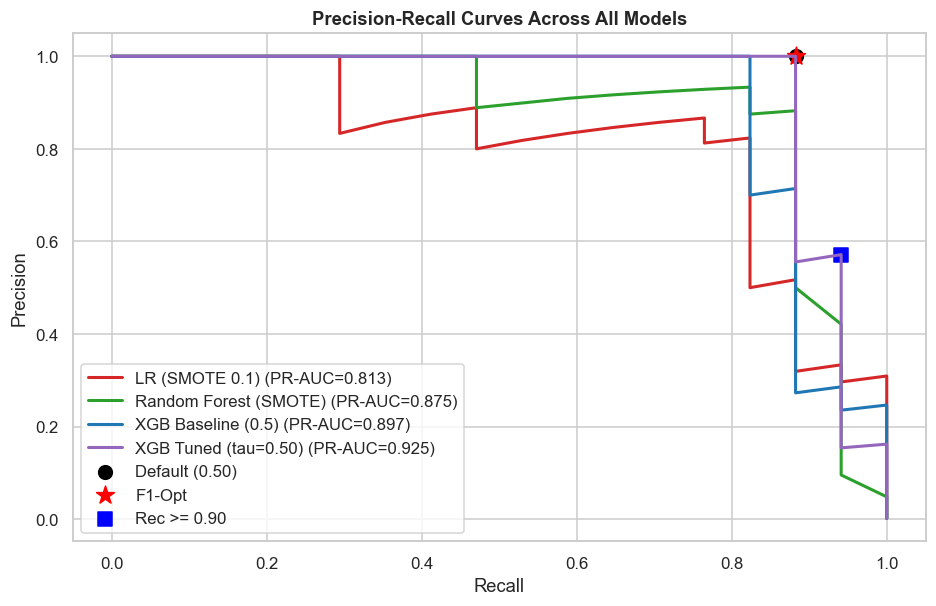

In [26]:
plt.figure(figsize=(10, 6))
for r, col in zip([res_lr_smote, res_rf, res_xgb_base, res_xgb_tuned_def], ['#d62728', '#2ca02c', '#1f77b4', '#9467bd']):
    p, rec, _ = precision_recall_curve(y_test, r['y_probs'])
    plt.plot(rec, p, label=f"{r['Model']} (PR-AUC={r['PR-AUC']:.3f})", color=col, lw=2)

plt.scatter([res_xgb_tuned_def['Recall']], [res_xgb_tuned_def['Precision']], color='black', s=80, label='Default (0.50)')
plt.scatter([res_xgb_tuned_f1['Recall']], [res_xgb_tuned_f1['Precision']], color='red', marker='*', s=150, label='F1-Opt')
plt.scatter([res_xgb_tuned_rec90['Recall']], [res_xgb_tuned_rec90['Precision']], color='blue', marker='s', s=80, label='Rec >= 0.90')
plt.title('Precision-Recall Curves Across All Models', fontweight='bold')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.show()

## Step 7: Business Simulation & Cost-Benefit Analysis

In [28]:
FRAUD_VALUE = 4500
REVIEW_COST = 150

sim_thresholds = sorted(list(set([0.10, 0.20, 0.30, 0.50, round(opt_f1_th, 2), round(opt_rec90_th, 2)])))
sim_results = []

for t in sim_thresholds:
    preds = (y_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    money_saved = tp * FRAUD_VALUE
    invest_cost = (tp + fp) * REVIEW_COST
    money_lost = fn * FRAUD_VALUE
    net_benefit = money_saved - invest_cost
    sim_results.append({
        'Threshold': t,
        'TP': tp, 'FP': fp, 'FN': fn,
        'Money Saved (₹)': f'₹{money_saved:,.0f}',
        'Review Cost (₹)': f'₹{invest_cost:,.0f}',
        'Money Lost (₹)': f'₹{money_lost:,.0f}',
        'Net Benefit (₹)': f'₹{net_benefit:,.0f}',
        '_raw_net': net_benefit
    })

df_sim = pd.DataFrame(sim_results)
print(df_sim.drop(columns=['_raw_net']).to_string(index=False))

best_th_row = max(sim_results, key=lambda x: x['_raw_net'])
optimal_biz_threshold = best_th_row['Threshold']
print(f"\nOptimal Business Threshold: {optimal_biz_threshold} with Net Benefit of {best_th_row['Net Benefit (₹)']}")

 Threshold  TP  FP  FN Money Saved (₹) Review Cost (₹) Money Lost (₹) Net Benefit (₹)
      0.01  16  12   1         ₹72,000          ₹4,200         ₹4,500         ₹67,800
      0.10  15   4   2         ₹67,500          ₹2,850         ₹9,000         ₹64,650
      0.20  15   1   2         ₹67,500          ₹2,400         ₹9,000         ₹65,100
      0.30  15   0   2         ₹67,500          ₹2,250         ₹9,000         ₹65,250
      0.50  15   0   2         ₹67,500          ₹2,250         ₹9,000         ₹65,250
      0.56  15   0   2         ₹67,500          ₹2,250         ₹9,000         ₹65,250

Optimal Business Threshold: 0.009999999776482582 with Net Benefit of ₹67,800


## Step 8: Pipeline & Deployment

#### 8.1 Sklearn Pipeline with Custom Feature Engineering & Scaling

In [29]:
class FraudFeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X_ = X.copy()
        if 'Amount' in X_.columns:
            X_['Amount_log'] = np.log1p(X_['Amount'])
        if 'Time' in X_.columns:
            X_['Hour'] = ((X_['Time'] % 86400) // 3600).astype(int)
        cols = [c for c in ['Time', 'Amount'] if c in X_.columns]
        X_.drop(columns=cols, inplace=True, errors='ignore')
        return X_

preprocessor = ColumnTransformer(
    transformers=[('num_scaler', StandardScaler(), ['Amount_log', 'Hour'])],
    remainder='passthrough'
)

pipeline = Pipeline([
    ('engineer', FraudFeatureEngineer()),
    ('scaler', preprocessor),
    ('classifier', best_xgb)
])

raw_train = df_sample.drop(columns=['Class']).iloc[X_train.index]
pipeline.fit(raw_train, y_train)

pipeline.optimal_threshold_ = float(optimal_biz_threshold)

joblib.dump(pipeline, 'fraud_detection_model.pkl')
print("Saved production pipeline to 'fraud_detection_model.pkl'")

Saved production pipeline to 'fraud_detection_model.pkl'


#### 8.2 Load and verify on 10 sample transactions

In [30]:
loaded_pipeline = joblib.load('fraud_detection_model.pkl')
sample_10 = df_sample.drop(columns=['Class']).head(10)

probs = loaded_pipeline.predict_proba(sample_10)[:, 1]
th = loaded_pipeline.optimal_threshold_
labels = (probs >= th).astype(int)

results = pd.DataFrame({
    'Txn': [f'TXN_{i+1}' for i in range(10)],
    'Amount': sample_10['Amount'].values,
    'Fraud_Probability': np.round(probs, 4),
    'Threshold': th,
    'Predicted_Label': labels,
    'Action': np.where(labels == 1, 'BLOCK / REVIEW', 'APPROVE')
})
print('\nInference Verification on 10 Live Transactions:')
print(results.to_string(index=False))


Inference Verification on 10 Live Transactions:
   Txn  Amount  Fraud_Probability  Threshold  Predicted_Label  Action
 TXN_1   38.31             0.0000       0.01                0 APPROVE
 TXN_2   37.89             0.0007       0.01                0 APPROVE
 TXN_3   70.00             0.0000       0.01                0 APPROVE
 TXN_4  145.50             0.0000       0.01                0 APPROVE
 TXN_5    1.00             0.0000       0.01                0 APPROVE
 TXN_6    0.89             0.0000       0.01                0 APPROVE
 TXN_7   47.30             0.0000       0.01                0 APPROVE
 TXN_8   46.25             0.0002       0.01                0 APPROVE
 TXN_9    0.99             0.0000       0.01                0 APPROVE
TXN_10   28.00             0.0000       0.01                0 APPROVE
